# Beijing battery electric vehicle

This notebook lists the 12 released days of one car, loads one day, and plots pack voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('beijing_ev')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('beijing_ev')
display(released)

,unit,vehicle,file,bytes,rows,first,last,mileage_first,mileage_last
0,2018-01-03,BEV,2018/2018.1.3.xlsx,96678,2610,2018-01-03 06:30:58,2018-01-03 14:27:02,54945,55132
1,2018-01-17,BEV,2018/2018.1.17.xlsx,84424,2237,2018-01-17 07:10:02,2018-01-17 14:43:58,57335,57525
2,2018-04-08,BEV,2018/2018.4.8.xlsx,95621,2565,2018-04-08 06:30:28,2018-04-08 15:05:32,71272,71500
3,2018-04-19,BEV,2018/2018.4.19.xlsx,86324,2328,2018-04-19 06:37:37,2018-04-19 16:26:31,73128,73360
4,2018-07-14,BEV,2018/2018.7.14.xlsx,95292,2593,2018-07-14 06:15:21,2018-07-14 17:09:43,88171,88447
5,2018-07-28,BEV,2018/2018.7.28.xlsx,97353,2685,2018-07-28 06:04:11,2018-07-28 17:45:27,90653,90927
6,2018-10-07,BEV,2018/2018.10.7.xlsx,98771,2920,2018-10-07 06:40:38,2018-10-07 18:41:08,103130,103356
7,2018-10-28,BEV,2018/2018.10.28.xlsx,137502,4023,2018-10-28 05:54:39,2018-10-28 14:58:33,107031,107262
8,2019-01-13,BEV,2019/2019.1.13.xlsx,100432,2705,2019-01-13 06:50:14,2019-01-13 17:59:05,120562,120762
9,2019-01-21,BEV,2019/2019.1.21.xlsx,84427,2214,2019-01-21 06:28:41,2019-01-21 14:16:05,121975,122163


Each row is one day of the same car, one workbook, with its first and last time and the odometer at the start and end of the day.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('beijing_ev', unit='2018-01-17')
print(frame.shape)
display(frame.head())

(2237, 6)


,time,speed,mileage,voltage,current,soc
0,20180117071002,0.0,57335,371.9,0.0,100
1,20180117071012,0.0,57335,370.7,0.0,100
2,20180117071022,9.1,57335,370.4,1.3,100
3,20180117071032,0.0,57335,370.5,0.9,100
4,20180117071042,0.0,57335,370.4,0.5,100


17 January 2018, one row about every 10 s. Time is a yyyymmddHHMMSS integer, as released.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['speed', 'voltage', 'current', 'soc']].describe().T)

,count,mean,std,min,25%,50%,75%,max
speed,2237.0,21.822620,22.757987,0.0,0.0,16.3,41.2,88.2
voltage,2237.0,338.133080,13.803267,310.1,327.6,332.4,349.1,371.9
current,2237.0,12.326732,28.123349,-60.6,0.7,2.3,19.5,189.3
soc,2237.0,59.368350,21.742336,20.0,43.0,57.0,79.0,100.0


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

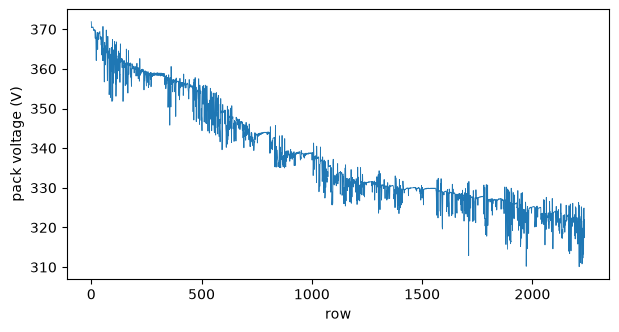

In [4]:
ax = frame['voltage'].plot(figsize=(7, 3.5), lw=0.6)
ax.set_xlabel('row')
ax.set_ylabel('pack voltage (V)')
plt.show()

Over the day pack voltage ranges from 310 to 372 V while SOC ranges from 100 down to 20 percent. Values are raw, as released.